# Оценка вероятности отмены бронирования отеля

## 1. Постановка задачи

Два отеля (City Hotel и Resort Hotel) принимают бронирования напрямую,
через турагентства, корпоративных партнёров и онлайн-платформы. Часть броней
отменяется, что создаёт простой номерного фонда и затрудняет планирование
загрузки. Если отель умеет заранее оценивать вероятность отмены, он может
принимать решения об овербукинге, корректировать тарифную политику
и требовать предоплату для «рискованных» броней.

**Цель задачи** – построить модель бинарной классификации, которая по
информации о бронировании предсказывает вероятность его отмены.

## 2. Формальная постановка

Дан набор [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand):
119 390 записей о бронированиях, 32 столбца.

**Объект** – одно бронирование (одна строка таблицы).

**Признаки** (31 столбец):

| №  | Признак                      | Смысл                                              |
|----|------------------------------|----------------------------------------------------|
| 1  | `hotel`                      | тип отеля (`City Hotel` / `Resort Hotel`)          |
| 2  | `lead_time`                  | число дней между оформлением брони и заездом       |
| 3  | `arrival_date_year`          | год заезда                                         |
| 4  | `arrival_date_month`         | месяц заезда                                       |
| 5  | `arrival_date_week_number`   | номер недели заезда в году                         |
| 6  | `arrival_date_day_of_month`  | день месяца заезда                                 |
| 7  | `stays_in_weekend_nights`    | число ночей в выходные                             |
| 8  | `stays_in_week_nights`       | число ночей в будни                                |
| 9  | `adults`                     | число взрослых                                     |
| 10 | `children`                   | число детей                                        |
| 11 | `babies`                     | число младенцев                                    |
| 12 | `meal`                       | тип питания                                        |
| 13 | `country`                    | страна гостя                                       |
| 14 | `market_segment`             | сегмент рынка                                      |
| 15 | `distribution_channel`       | канал дистрибуции                                  |
| 16 | `is_repeated_guest`          | повторный ли гость (0/1)                           |
| 17 | `previous_cancellations`     | число предыдущих отмен брони клиентом                             |
| 18 | `previous_bookings_not_canceled` | число предыдущих успешных броней               |
| 19 | `reserved_room_type`         | зарезервированный тип номера                       |
| 20 | `assigned_room_type`         | фактически назначенный тип номера                  |
| 21 | `booking_changes`            | число изменений брони                              |
| 22 | `deposit_type`               | тип депозита                                       |
| 23 | `agent`                      | идентификатор турагенства                               |
| 24 | `company`                    | идентификатор компании                             |
| 25 | `days_in_waiting_list`       | число дней в листе ожидания                        |
| 26 | `customer_type`              | тип бронирования                                        |
| 27 | `adr`                        | средняя цена за ночь (Average Daily Rate)          |
| 28 | `required_car_parking_spaces`| число требуемых парковочных мест                   |
| 29 | `total_of_special_requests`  | число специальных пожеланий                        |
| 30 | `reservation_status`         | итоговый статус брони                              |
| 31 | `reservation_status_date`    | дата установления последнего статуса                          |

Столбцы 30 и 31 (`reservation_status`, `reservation_status_date`) будут
исключены из модели по причине утечки целевой переменной – см. пункт 3.

**Целевая переменная** – столбец `is_canceled`:

- `1` – бронирование не состоялось: гость отменил его заранее (`Canceled`)
  или не приехал и не отменил (`No-Show`);
- `0` – бронирование состоялось: гость заселился и завершил проживание
  (`Check-Out`).

Тип задачи – **бинарная классификация**: по признакам объекта
предсказать целевую переменную, принимающую два значения.

## 3. Утечка целевой переменной

Столбцы `reservation_status` и `reservation_status_date` по смыслу отражают
итог бронирования. Использование их в качестве признаков означало бы
подсказку ответа модели. Оба столбца удаляются до обучения.

## 4. План работы

1. Прочитать данные.
2. Разбить данные на обучающую и тестовую выборки.
3. Визуализировать данные и вычислить основные характеристики (среднее,
   разброс, корреляционную матрицу и т.д.). Интерпретировать.
4. Разобраться с выбросами. Если они есть.
5. Обработать пропущенные значения (или убедиться, что их нет).
6. Обработать категориальные признаки.
7. Провести нормализацию (или объяснить, почему в данном случае она не нужна).
8. Запустить классификатор ближайших соседей или другой метод
   (аргументировать выбор!).
9. Вычислить ошибки на обучающей и тестовой выборках. Напечатать матрицы
   рассогласования. Прокомментировать. Выбрать
   оптимальное значение гиперпараметра (количества ближайших соседей).
10. По желанию: запустить другие классификаторы. Сравнить результаты.
11. По желанию: как-то побороться с несбалансированностью классов (если она  есть).
12. По желанию: исключить коррелированные переменные (объяснить зачем).
13. Сделать общие выводы.

In [1]:
import numpy as np              # Одномерные и многомерные массивы (array)
import pandas as pd             # Таблицы и временные ряды (dataframe, series)
import matplotlib.pyplot as plt # Научная графика
import seaborn as sns           # Еще больше красивой графики для визуализации данных
import sklearn                  # Алгоритмы машинного обучения

Настройки для красивого вывода в Colab

In [2]:
sns.set_theme(style="whitegrid") # Белый фон с серой сеткой
pd.set_option("display.max_columns", 100) # Лимит на отрисовку столбцов

# Пункт 1. Чтение данных

In [ ]:
path = 'C:\\Machine Learning (Practical Exercises)\\ML_practical_tasks\\Hometask_23_10_2026\\hotel_bookings.csv' # Путь к датасету
data_raw = pd.read_csv(path)

In [4]:
print("Тип данных:")
type(data_raw)

Тип данных:


pandas.DataFrame

In [5]:
print("Размер таблицы (строки, столбцы):")
data_raw.shape

Размер таблицы (строки, столбцы):


(119390, 32)

In [6]:
print("Таблица:\n")
data_raw

Таблица:



,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [7]:
print("Первые 20 строк:")
data_raw.head(20)

Первые 20 строк:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,107.00,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,0.0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,NaN,0,Transient,103.00,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,82.00,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,0,No Deposit,15.0,NaN,0,Transient,105.50,0,0,Canceled,2015-04-22


In [8]:
print("Последние 20 строк:")
data_raw.tail(20)

Последние 20 строк:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119370,City Hotel,0,201,2017,August,35,30,1,4,1,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,108.00,0,2,Check-Out,2017-09-04
119371,City Hotel,0,175,2017,August,35,31,1,3,2,0.0,0,BB,NLD,Offline TA/TO,TA/TO,0,0,0,A,A,1,No Deposit,42.0,NaN,0,Transient,86.85,0,2,Check-Out,2017-09-04
119372,City Hotel,0,175,2017,August,35,31,1,3,1,0.0,0,BB,NLD,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,42.0,NaN,0,Transient,82.35,0,1,Check-Out,2017-09-04
119373,City Hotel,0,175,2017,August,35,31,1,3,1,0.0,0,BB,NLD,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,42.0,NaN,0,Transient,82.35,0,1,Check-Out,2017-09-04
119374,City Hotel,0,201,2017,August,35,29,1,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,117.00,0,2,Check-Out,2017-09-04
119375,City Hotel,0,200,2017,August,35,30,1,4,2,0.0,0,BB,AUT,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,16.0,NaN,0,Transient,85.50,0,1,Check-Out,2017-09-04
119376,City Hotel,0,165,2017,August,35,29,1,5,3,0.0,0,BB,AUT,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,209.25,0,3,Check-Out,2017-09-04
119377,City Hotel,0,185,2017,August,35,30,1,4,2,0.0,0,SC,CHE,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,99.00,0,1,Check-Out,2017-09-04
119378,City Hotel,0,247,2017,August,35,31,1,3,2,0.0,0,BB,GBR,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,42.0,NaN,0,Transient,86.85,0,0,Check-Out,2017-09-04
119379,City Hotel,0,109,2017,August,35,31,1,3,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,155.00,0,1,Check-Out,2017-09-04


In [9]:
print("Случайные 10 строк:")
data_raw.sample(10)

Случайные 10 строк:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
18561,Resort Hotel,0,105,2015,November,47,18,2,4,2,0.0,0,Undefined,ESP,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,313.0,NaN,65,Transient-Party,69.00,0,0,Check-Out,2015-11-24
16911,Resort Hotel,0,0,2015,September,38,16,0,1,1,0.0,0,BB,USA,Direct,Direct,0,0,0,A,C,0,No Deposit,250.0,NaN,0,Group,65.00,0,0,Check-Out,2015-09-17
29186,Resort Hotel,0,386,2016,October,43,20,0,3,2,0.0,0,BB,GBR,Groups,Corporate,0,0,0,A,D,1,No Deposit,NaN,NaN,0,Transient-Party,49.00,0,0,Check-Out,2016-10-23
101457,City Hotel,0,3,2016,November,46,9,0,4,2,2.0,0,BB,FRA,Online TA,TA/TO,0,0,0,F,F,0,No Deposit,9.0,NaN,0,Transient,246.25,0,1,Check-Out,2016-11-13
65855,City Hotel,1,248,2017,April,15,9,2,0,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,No Deposit,58.0,NaN,0,Transient-Party,80.00,0,0,Canceled,2017-04-04
110485,City Hotel,0,76,2017,April,17,24,1,3,2,0.0,0,HB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,42.0,NaN,0,Transient,128.16,0,0,Check-Out,2017-04-28
85103,City Hotel,0,8,2016,March,11,6,2,2,2,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,103.00,0,0,Check-Out,2016-03-10
26245,Resort Hotel,0,183,2017,July,30,24,1,3,2,0.0,0,BB,PRT,Direct,Direct,1,0,0,D,D,0,No Deposit,250.0,NaN,0,Group,142.94,0,1,Check-Out,2017-07-28
76003,City Hotel,1,336,2015,September,38,18,0,2,2,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,1,0,A,A,0,Non Refund,6.0,NaN,0,Transient-Party,101.50,0,0,Canceled,2015-07-06
68197,City Hotel,1,104,2017,May,20,15,1,2,1,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,160.00,0,0,Canceled,2017-01-31


In [10]:
print("Сводка о структуре датасета:")
data_raw.info()

Сводка о структуре датасета:
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12

# Пункт 2. Разбиение данных на обучающую и тестовую выборки

Удаляем столбцы с утечкой, о которых писали в пункте 0:

In [11]:
data = data_raw.drop(['reservation_status', 'reservation_status_date'], axis = 1)
data

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.00,0,0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0


Отделяем целевую переменную (y) от признаков (X):

In [12]:
X = data.drop(['is_canceled'], axis=1)
y = data['is_canceled']

In [13]:
print("Тип данных:")
type(X)

Тип данных:


pandas.DataFrame

In [14]:
print("Тип данных:")
type(y)

Тип данных:


pandas.Series

Разобьем данные на обучающую и тестовую выборки в пропорции 3:1 (75% - обучающая выборка, 25% - тестовая).
- stratify=y гарантирует, что пропорция отмен (37% на 63%) сохранится и в обучающей, и в тестовой выборках

In [15]:
from sklearn.model_selection import train_test_split # Функция для разбиения на обучающую и тестовую выборки

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42, stratify = y)

Выводим размеры получившихся выборок:

In [16]:
N_train, d = X_train.shape # вернёт (строки, столбцы)
N_test, d = X_test.shape # вернёт (строки, столбцы)

print("Размер обучающей выборки (N, d):", N_train, d)
print("Размер тестовой выборки (N, d):", N_test, d)

Размер обучающей выборки (N, d): 89542 29
Размер тестовой выборки (N, d): 29848 29


Проверка сохранения баланса:

In [17]:
print("\nПроверка баланса классов в Train:")
print(y_train.value_counts(normalize=True).round(2))
print("\nПроверка баланса классов в Test:")
print(y_test.value_counts(normalize=True).round(2))


Проверка баланса классов в Train:
is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64

Проверка баланса классов в Test:
is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64


Восстанавление таблиц обучающей и тестовой выборок для работы с последующими пунктами:

In [18]:
data_train = X_train.copy()
data_train['is_canceled'] = y_train

data_test = X_test.copy()
data_test['is_canceled'] = y_test

print("Размер обучающей выборки:", data_train.shape)
print("Размер тестовой выборки:", data_test.shape)

Размер обучающей выборки: (89542, 30)
Размер тестовой выборки: (29848, 30)


# Пункт 3. Визуализация данных и основные характеристики

## Пункт 3.1. Визуализация связи двух главных признаков с целевой переменной

Возьмем два самых важных числовых признака – число дней между оформлением брони и заездом `lead_time` и среднюю цену за ночь `adr`, и раскрасим точки в зависимости от того, была ли отменена бронь `is_canceled = 1` или нет `is_canceled = 0`. Используем параметр `alpha` для прозрачности, чтобы видеть плотность скопления точек.

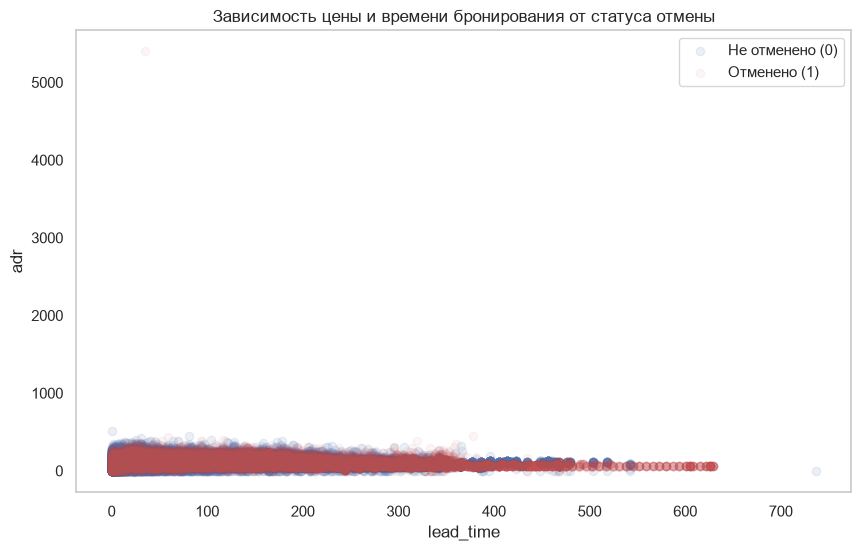

In [19]:
plt.figure(figsize=(10, 6))

# Брони, которые НЕ отменены (класс 0), рисуем синим
plt.scatter(data_train[data_train['is_canceled'] == 0]['lead_time'],
            data_train[data_train['is_canceled'] == 0]['adr'],
            alpha=0.1, label='Не отменено (0)', color='b')

# Брони, которые ОТМЕНЕНЫ (класс 1), рисуем красным
plt.scatter(data_train[data_train['is_canceled'] == 1]['lead_time'],
            data_train[data_train['is_canceled'] == 1]['adr'],
            alpha=0.05, label='Отменено (1)', color='r')

plt.xlabel('lead_time')
plt.ylabel('adr')
plt.title('Зависимость цены и времени бронирования от статуса отмены')
plt.legend()
plt.grid()
plt.show()

Более информативный вариант графика:

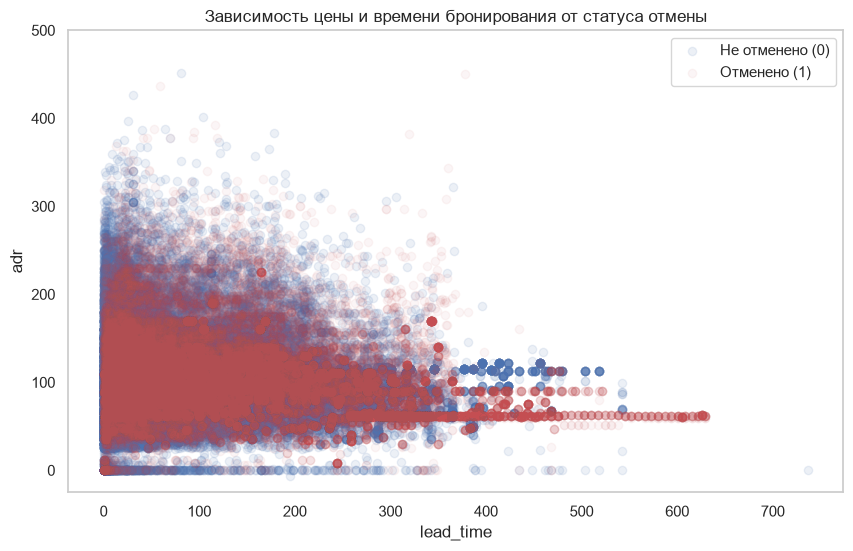

In [20]:
plt.figure(figsize=(10, 6))

# Брони, которые НЕ отменены (класс 0), рисуем синим
plt.scatter(data_train[data_train['is_canceled'] == 0]['lead_time'],
            data_train[data_train['is_canceled'] == 0]['adr'],
            alpha=0.1, label='Не отменено (0)', color='b')

# Брони, которые ОТМЕНЕНЫ (класс 1), рисуем красным
plt.scatter(data_train[data_train['is_canceled'] == 1]['lead_time'],
            data_train[data_train['is_canceled'] == 1]['adr'],
            alpha=0.05, label='Отменено (1)', color='r')

plt.xlabel('lead_time')
plt.ylabel('adr')
plt.title('Зависимость цены и времени бронирования от статуса отмены')
plt.legend()
plt.grid()
plt.ylim(-25, 500)
plt.show()

На графике видно, что в левой части (где `lead_time` маленький) преобладают синие точки. Чем правее мы двигаемся (время бронирования увеличивается), тем больше становится красных точек. Это согласуется с положительной корреляцией между `lead_time` и целевой переменной `is_canceled`. Можно предположить, что раннее бронирование `lead_time` сильно повышает вероятность отмены.

## Пункт 3.2. Матрица рассеивания (диаграммы рассеивания)

Поскольку у нас 30 признаков (2 признака удалили), строить полную матрицу нельзя (она будет нечитаемой). Выберем 4 ключевых числовых признака и построим матрицу только для них: число дней между оформлением брони и заездом `lead_time`, средняя цена за ночь `adr`, количество спецзапросов `total_of_special_requests` и количество изменений брони `booking_changes`.

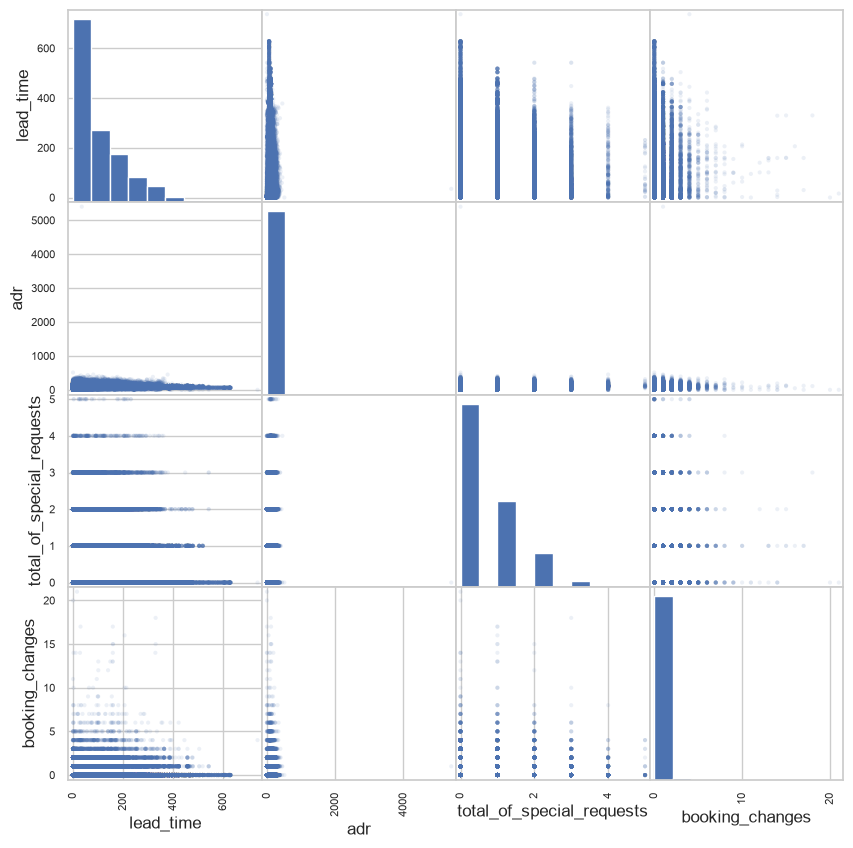

In [21]:
# Выбираем 4 показательных числовых признака
cols_to_plot = ['lead_time', 'adr', 'total_of_special_requests', 'booking_changes']

# Строим матрицу рассеяния
pd.plotting.scatter_matrix(data_train[cols_to_plot], alpha=0.1, figsize=(10, 10))
pass

- Признаки `lead_time` и `adr` имеют правостороннюю асимметрию: большинство значений находится в нижней части шкалы, при этом распределения имеют длинные хвосты в сторону больших значений.
- Признаки `total_of_special_requests` и `booking_changes` являются дискретными и смещены к нулю — у подавляющего большинства броней нет особых запросов и изменений.
- Между признаками нет явных линейных зависимостей (облака точек не вытянуты в прямые линии).
- На всех графиках отчетливо видны выбросы (одинокие точки, улетевшие далеко от основного скопления), особенно по признакам `adr` (до 5000) и `booking_changes` (до 20).
- При значении `adr = 0` наблюдается скопление точек в виде сплошной линии. Это свидетельствует о наличии в датасете броней с нулевой стоимостью. Поскольку бесплатное проживание не является стандартным бизнес-процессом, такие записи требуют дополнительной проверки и будут рассмотрены при обработке выбросов.

## Пункт 3.3. Вычисление среднего значения

In [22]:
data_train.describe().T

,count,mean,std,min,25%,50%,75%,max
lead_time,89542.0,103.770700,106.839109,0.00,18.0000,69.0,160.0,737.0
arrival_date_year,89542.0,2016.155123,0.706845,2015.00,2016.0000,2016.0,2017.0,2017.0
arrival_date_week_number,89542.0,27.147316,13.616581,1.00,16.0000,27.0,38.0,53.0
arrival_date_day_of_month,89542.0,15.808481,8.794451,1.00,8.0000,16.0,23.0,31.0
stays_in_weekend_nights,89542.0,0.927330,0.999638,0.00,0.0000,1.0,2.0,19.0
stays_in_week_nights,89542.0,2.498827,1.911470,0.00,1.0000,2.0,3.0,50.0
adults,89542.0,1.855554,0.590591,0.00,2.0000,2.0,2.0,55.0
children,89538.0,0.103487,0.397524,0.00,0.0000,0.0,0.0,10.0
babies,89542.0,0.007751,0.098832,0.00,0.0000,0.0,0.0,10.0
is_repeated_guest,89542.0,0.031494,0.174648,0.00,0.0000,0.0,0.0,1.0


Что выводит метод `describe()` для числовых столбцов (int, float):
- count – число непустых (не NaN) значений.
- mean – среднее арифметическое значение (**то, что нужно в данном пунтке**).
- std – стандартное отклонение (разброс данных) от mean.
- min – минимальное значение.
- 25% – первый квартиль (нижняя четверть данных).
- 50% – медиана (второй квартиль).
- 75% – третий квартиль (верхняя четверть данных).
- max – максимальное значение.

**Целевая переменная `is_canceled`**: Среднее значение `is_canceled` равно 0.37 (так как 1 – это отмена, а 0 – нет). Это значит, что в среднем 37% броней отменяется. Это подтверждает дисбаланс классов (классы представлены неравномерно).

**Время бронирования `lead_time`**: Среднее число дней между оформлением брони и заездом составляет около 104 дней.

**Цена `adr`**: Средняя цена за ночь – около 102.

**Посетители (клиенты: `adults`, `children`, `babies`)**: В среднем на одну бронь приходится 1.85 взрослых, 0.10 детей и 0.008 младенцев.

**Число дней в листе ожидания `days_in_waiting_list`**: Медиана равна 0, но среднее – 2.30. Это говорит о том, что подавляющее большинство броней оформляются сразу (без ожидания), а высокое среднее возникает из-за редких аномальных выбросов.

## Пункт 3.4. Вычисление разброса данных

Разброс оценивается по стандартному отклонению `std`, полному размаху `max - min` и межквартильному размаху `75% - 25%`, а показатели центра – среднее `mean` и медиана `50%` – используются как обязательные точки отсчета для определения масштаба и симметричности этого разброса в рамках одного вывода `describe()`.

In [23]:
# Получаем базовую таблицу статистик
stats = data_train.describe().T

# Явно вычисляем полный размах и межквартильный размах
stats['full_range'] = stats['max'] - stats['min'] # Полный размах
stats['IQR'] = stats['75%'] - stats['25%']        # Межквартильный размах

# Выводим только нужные колонки (центр, разброс, границы)
stats[['mean', '50%', 'std', 'min', '25%', '75%', 'max', 'full_range', 'IQR']]

,mean,50%,std,min,25%,75%,max,full_range,IQR
lead_time,103.770700,69.0,106.839109,0.00,18.0000,160.0,737.0,737.00,142.0000
arrival_date_year,2016.155123,2016.0,0.706845,2015.00,2016.0000,2017.0,2017.0,2.00,1.0000
arrival_date_week_number,27.147316,27.0,13.616581,1.00,16.0000,38.0,53.0,52.00,22.0000
arrival_date_day_of_month,15.808481,16.0,8.794451,1.00,8.0000,23.0,31.0,30.00,15.0000
stays_in_weekend_nights,0.927330,1.0,0.999638,0.00,0.0000,2.0,19.0,19.00,2.0000
stays_in_week_nights,2.498827,2.0,1.911470,0.00,1.0000,3.0,50.0,50.00,2.0000
adults,1.855554,2.0,0.590591,0.00,2.0000,2.0,55.0,55.00,0.0000
children,0.103487,0.0,0.397524,0.00,0.0000,0.0,10.0,10.00,0.0000
babies,0.007751,0.0,0.098832,0.00,0.0000,0.0,10.0,10.00,0.0000
is_repeated_guest,0.031494,0.0,0.174648,0.00,0.0000,0.0,1.0,1.00,0.0000


**Оценка масштаба (std относительно mean)**:
Стандартное отклонение (std) показывает плотность данных.
- Если std близок к mean или больше него – разброс огромный. Например, у признака `lead_time` std (106.8) почти равно mean (103.8). Это означает колоссальный разброс: клиенты ведут себя совершенно по-разному.
- Для признака `adr` std (51.2) составляет половину от mean (101.8). Это говорит о том, что цены всё же группируются вокруг среднего, но разброс всё равно ощутимый.

**Расчет границ ядра (IQR = 75% - 25%)**:
Межквартильный размах показывает ширину коридора, в котором лежат 50% самых типичных данных (без учета выбросов).
- Для `lead_time` IQR = 142 (от 18 до 160 дней). Половина клиентов бронирует в этом адекватном диапазоне.
- Для `adr` IQR = 56.6 (от 69.3 до 126). Это типичный ценовой коридор.

**Расчет абсолютных границ (Full range = max - min) и поиск выбросов**:
Сравниваем полный размах с IQR. Если полный размах в разы больше IQR, в данных есть аномалии.
- `lead_time`: Полный размах = 737 (от 0 до 737). Это в 5 раз больше IQR (737 / 142). Значит, есть люди, бронирующие за 2 года, но их мало.
- `adr`: Полный размах = 5406 (от -6.38 до 5400). Это почти в 95 раз больше IQR. Это критическая аномалия. Наличие отрицательных цен и экстремально высоких значений требует проверки. В рамках дальнейшей обработки аномальные значения будут заменяться медианой признака без удаления строк.
- `days_in_waiting_list`: Полный размах = 391, при IQR = 0. Все 75% клиентов имеют 0 дней ожидания, но редкие выбросы растягивают шкалу.

**Проверка симметрии (mean относительно 50%)**:
Сравниваем среднее и медиану, чтобы понять, куда вытянут «хвост».
- `lead_time`: mean (103.8) > median (69.0). Разброс сильно вытянут вправо (длинный хвост из тех, кто бронирует очень заранее).
- `adr`: mean (101.8) > median (94.5). Небольшая правосторонняя асимметрия (дорогие номера тянут среднее вверх).
- `days_in_waiting_list`: mean (2.30) > median (0.0). Экстремальная асимметрия вправо из-за редких выбросов.

**Примечание**: Признаки `booking_changes`, `children`, `babies` полностью смещены влево (медиана = 0, среднее близко к 0), так как у большинства клиентов их просто нет.

**Общий вывод**:
Анализ разброса показал, что данные крайне неоднородны и имеют сильную правостороннюю асимметрию. Сравнение полного размаха с межквартильным (IQR) выявило наличие экстремальных выбросов, особенно в признаках `adr` и `lead_time`. Без их предварительной очистки (пункт 4) алгоритмы машинного обучения будут работать некорректно

## Пункт 3.5. Вычисление корреляционной матрицы

Вычисляем корреляционную матрицу с помощью метода `corr()`, который показывает линейную связь между признаками. Значения лежат в диапазоне от -1 до 1. Близость к 1 означает прямую зависимоть (чем больше один признак, тем больше другой), к -1 – обратную зависимость. Близость к 0 означает, что связи нет.

In [24]:
data_train.corr(numeric_only=True) # numeric_only=True – только количественные (числовые) признаки.

,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,is_canceled
lead_time,1.000000,0.041647,0.125951,-0.000183,0.086780,0.164773,0.117617,-0.036732,-0.018998,-0.123759,0.087549,-0.072944,-0.000269,-0.069516,0.152913,0.164724,-0.060333,-0.116420,-0.097822,0.293169
arrival_date_year,0.041647,1.000000,-0.540217,0.001761,0.020617,0.027123,0.028688,0.055615,-0.012414,0.009278,-0.120010,0.029364,0.028566,0.062067,0.262967,-0.060261,0.194165,-0.013043,0.105215,0.018449
arrival_date_week_number,0.125951,-0.540217,1.000000,0.065016,0.018568,0.016279,0.023188,0.006795,0.012512,-0.028170,0.036040,-0.021511,0.008754,-0.030508,-0.080563,0.023740,0.074630,0.001166,0.029580,0.006810
arrival_date_day_of_month,-0.000183,0.001761,0.065016,1.000000,-0.017640,-0.030222,-0.003099,0.015969,0.001207,-0.002595,-0.027687,-0.003325,0.009594,0.001216,0.041918,0.019717,0.031509,0.005890,0.003936,-0.007044
stays_in_weekend_nights,0.086780,0.020617,0.018568,-0.017640,1.000000,0.501604,0.088362,0.045848,0.017231,-0.084636,-0.012489,-0.040915,0.069155,0.139483,0.066578,-0.055630,0.049160,-0.017532,0.069691,0.001395
stays_in_week_nights,0.164773,0.027123,0.016279,-0.030222,0.501604,1.000000,0.091696,0.043621,0.019261,-0.096036,-0.014762,-0.049388,0.101090,0.182934,0.181684,-0.000035,0.063206,-0.023375,0.066047,0.025793
adults,0.117617,0.028688,0.023188,-0.003099,0.088362,0.091696,1.000000,0.030474,0.016119,-0.145917,-0.007429,-0.105748,-0.050698,-0.035300,0.206585,-0.009183,0.223821,0.014209,0.122296,0.056896
children,-0.036732,0.055615,0.006795,0.015969,0.045848,0.043621,0.030474,1.000000,0.025635,-0.032468,-0.024516,-0.021060,0.050459,0.043088,0.027540,-0.033813,0.321926,0.056847,0.082848,0.006689
babies,-0.018998,-0.012414,0.012512,0.001207,0.017231,0.019261,0.016119,0.025635,1.000000,-0.008965,-0.007173,-0.006634,0.082012,0.033985,0.021630,-0.010323,0.028386,0.038121,0.093368,-0.030904
is_repeated_guest,-0.123759,0.009278,-0.028170,-0.002595,-0.084636,-0.096036,-0.145917,-0.032468,-0.008965,1.000000,0.082863,0.420319,0.011247,0.029028,-0.253706,-0.022155,-0.132520,0.074018,0.013722,-0.085617


Для удобства отсортируем признаки по их корреляции с целевой переменной в порядке убывания (ascending=False).

In [25]:
corr_with_target = data_train.corr(numeric_only=True)['is_canceled'].sort_values(ascending=False)
corr_with_target

is_canceled                       1.000000
lead_time                         0.293169
previous_cancellations            0.111057
adults                            0.056896
days_in_waiting_list              0.053385
adr                               0.046965
stays_in_week_nights              0.025793
arrival_date_year                 0.018449
arrival_date_week_number          0.006810
children                          0.006689
stays_in_weekend_nights           0.001395
arrival_date_day_of_month        -0.007044
company                          -0.017387
babies                           -0.030904
previous_bookings_not_canceled   -0.058291
agent                            -0.079049
is_repeated_guest                -0.085617
booking_changes                  -0.141621
required_car_parking_spaces      -0.194613
total_of_special_requests        -0.237629
Name: is_canceled, dtype: float64

На основе корреляционной матрицы (рассчитанной только для числовых признаков методом `corr()`) можно сделать следующие выводы:

**Связь признаков с целевой переменной (`is_canceled`):**
- **Положительная связь (увеличивают шанс отмены):**
  - `lead_time` (**+0.29**) – главный фактор. Чем больше времени проходит между бронированием и заездом, тем выше вероятность отмены.
  - `previous_cancellations` (**+0.11**) – если клиент отменял брони раньше, он с большой вероятностью сделает это снова.
- **Отрицательная связь (снижают шанс отмены):**
  - `total_of_special_requests` (**-0.24**) – чем больше у гостя особых пожеланий, тем сильнее он привязан к этой брони и тем реже её отменяет.
  - `required_car_parking_spaces` (**-0.19**) – наличие парковки также удерживает клиента.
  - `booking_changes` (**-0.14**) – интересный факт: если клиент вносил изменения в бронь (менял даты, номер), он реже её полностью отменяет (видимо, проявляет заинтересованность).
  - `is_repeated_guest` (**-0.09**) – постоянные гости реже отменяют брони.

**Связи между признаками:**
- **`arrival_date_year` и `arrival_date_week_number` (сильная отрицательная связь -0.54).** Это логично с точки зрения календаря (с наступлением нового года номер недели сбрасывается), однако для модели машинного обучения эти два признака могут создавать путаницу.
- **`stays_in_weekend_nights` и `stays_in_week_nights` (положительная связь +0.50).** Если человек бронирует номер на будни, он с высокой вероятностью забронирует и выходные.
- **`is_repeated_guest` и `previous_bookings_not_canceled` (+0.42).** Постоянные гости имеют историю успешных броней.

**Ограничения метода:**
- В матрицу попали только числовые признаки. Категориальные данные (например, `deposit_type`, `market_segment`, `hotel`), которые сильно влияют на отмену, метод `corr()` не учитывает.

## Пункт 3.6. Другое

### Статистика категориальных признаков:

In [26]:
data_train.describe(include = ['object']).T

C:\Users\Никита\AppData\Local\Temp\ipykernel_9480\3502369023.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data_train.describe(include = ['object']).T


,count,unique,top,freq
hotel,89542,2,City Hotel,59661
arrival_date_month,89542,12,August,10350
meal,89542,5,BB,69289
country,89165,167,PRT,36479
market_segment,89542,8,Online TA,42411
distribution_channel,89542,5,TA/TO,73535
reserved_room_type,89542,10,A,64584
assigned_room_type,89542,12,A,55620
deposit_type,89542,3,No Deposit,78453
customer_type,89542,4,Transient,67151


Что выводит метод `describe()` для текстовых/категориальных столбцов (object, string)
- count – число непустых (не NaN) значений.
- unique – количество уникальных элементов.
- top – самое часто встречающееся значение.
- freq – частота (сколько раз повторяется top)

### Получение уникальных значений для нескольких важных признаков:

Уникальные значения в `hotel`:

In [27]:
data_train['hotel'].unique()

<StringArray>
['City Hotel', 'Resort Hotel']
Length: 2, dtype: str

Уникальные значения в `deposit_type`:

In [28]:
data_train['deposit_type'].unique()

<StringArray>
['No Deposit', 'Non Refund', 'Refundable']
Length: 3, dtype: str

Уникальные значения `customer_type`:

In [29]:
data_train['customer_type'].unique()

<StringArray>
['Transient', 'Contract', 'Transient-Party', 'Group']
Length: 4, dtype: str

Уникальные значения `market_segment`:

In [30]:
data_train['market_segment'].unique()

<StringArray>
[    'Online TA',        'Groups',        'Direct',     'Corporate',
 'Offline TA/TO', 'Complementary',      'Aviation',     'Undefined']
Length: 8, dtype: str

### Пропущенные значения:

Полная таблица пропусков:

In [31]:
data_train.isnull()

,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,is_canceled
67110,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
95128,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
49525,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
51609,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
73555,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83701,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
104906,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
36939,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
54811,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False


Количество пропусков по признакам (сумма пропусков):

In [32]:
data_train.isnull().sum()

hotel                                 0
lead_time                             0
arrival_date_year                     0
arrival_date_month                    0
arrival_date_week_number              0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                              4
babies                                0
meal                                  0
country                             377
market_segment                        0
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
assigned_room_type                    0
booking_changes                       0
deposit_type                          0
agent                             12239
company                           84460
days_in_waiting_list                  0


Количество объектов (строк) в обучающей выборке:

In [33]:
len(data_train)

89542

Метод `isnull().sum()` выявил четыре столбца с пропусками в обучающей выборке `data_train`:
- `company` – 84 460 пропуска (около 94% данных отсутствует);
- `agent` – 12 239 пропусков;
- `country` – 377 пропусков;
- `children` – 4 пропуска.

Все эти пропуски необходимо обработать в пункте 5. Также пропуски `data_test` будут найдены в пункте 5.

# Пункт 4. Обнаружение и обработка выбросов

Для формального обнаружения выбросов воспользуемся правилом «1.5 межквартильных размаха (IQR)» (**эвристика Тьюки**). Выбросами считаются значения, которые лежат ниже $[Q_1-1.5\times{\rm IQR}]$ или выше $[Q_3+1.5\times{\rm IQR}]$. После обнаружения мы не будем удалять строки, а заменим аномальные значения на медиану, чтобы сохранить данные о других признаках.

## Пункт 4.1. Обнаружение выбросов

Объявляем функцию для поиска выбросов по методу «1.5 межквартильных размаха (IQR)»:

In [34]:
def find_outliers_bounds(data_, column): # "Найти_выбросов_границы". data_ - таблица; column - признак.
    Q1 = data_[column].quantile(0.25)
    Q3 = data_[column].quantile(0.75)
    IQR = Q3 - Q1 # Межквартильный размах
    lower_bound = Q1 - 1.5 * IQR # Нижняя граница
    upper_bound = Q3 + 1.5 * IQR # Верхняя граница
    # Если нижняя граница ушла в минус (а цена/время не могут быть отрицательными), то ставим 0
    if lower_bound < 0:
        lower_bound = 0
    return lower_bound, upper_bound

Создаём таблицу с количеством выбросов признаков `adr`, `lead_time` и `adults` на обучающей выборке `data_train`:

In [35]:
train_outliers_dict = {
    'adr': [0],
    'lead_time': [0],
    'adults': [0]
}
total_train_data_outliers = pd.DataFrame(train_outliers_dict)
total_train_data_outliers

,adr,lead_time,adults
0,0,0,0


Создаём таблицу с количеством выбросов признаков `adr`, `lead_time` и `adults` на тестовой выборке `data_test`:

In [36]:
test_outliers_dict = {
    'adr': [0],
    'lead_time': [0],
    'adults': [0]
}
total_test_data_outliers = pd.DataFrame(test_outliers_dict)
total_test_data_outliers

,adr,lead_time,adults
0,0,0,0


Находим границы для ключевых признаков `adr` (средняя цена за ночь) и `lead_time` (число дней между оформлением брони и заездом) и количество их выбросов. Обнаружение проблемы выбросов в этих признаках – в пункте 3.

Обучающая выборка `data_train`:

In [37]:
for col in ['adr', 'lead_time']:
    lb, ub = find_outliers_bounds(data_train, col) # Получаем нижнюю и верхнюю границы выбросов
    outliers_mask = (data_train[col] < lb) | (data_train[col] > ub) # Создаем маску (фильтр) для выбросов
    outliers_data = data_train[outliers_mask] # Применяем маску к таблице (оставляем только выбросы)
    total_train_data_outliers.at[0, col] = len(outliers_data) # Считаем количество выбросов
    print(f"Признак '{col}': Нижняя граница = {lb:.2f}, Верхняя граница = {ub:.2f}. Найдено выбросов: {total_train_data_outliers.at[0, col]}")

Признак 'adr': Нижняя граница = 0.00, Верхняя граница = 210.97. Найдено выбросов: 2864
Признак 'lead_time': Нижняя граница = 0.00, Верхняя граница = 373.00. Найдено выбросов: 2235


Тестовая выборка `data_test`:

In [38]:
for col in ['adr', 'lead_time']:
    lb, ub = find_outliers_bounds(data_train, col) # Получаем нижнюю и верхнюю границы выбросов (границы  не меняем)
    outliers_mask = (data_test[col] < lb) | (data_test[col] > ub) # Создаем маску (фильтр) для выбросов
    outliers_data = data_test[outliers_mask] # Применяем маску к таблице (оставляем только выбросы)
    total_test_data_outliers.at[0, col] = len(outliers_data) # Считаем количество выбросов
    print(f"Признак '{col}': Нижняя граница = {lb:.2f}, Верхняя граница = {ub:.2f}. Найдено выбросов: {total_test_data_outliers.at[0, col]}")

Признак 'adr': Нижняя граница = 0.00, Верхняя граница = 210.97. Найдено выбросов: 996
Признак 'lead_time': Нижняя граница = 0.00, Верхняя граница = 373.00. Найдено выбросов: 770


Бронь с 0 взрослых `adults` – это ошибка (детей `children` и младенцев `babies` без взрослых не заселяют).

Бронь с более, чем 10 взрослыми `adults` – также явная ошибка, так как один стандартный гостиничный номер не может вместить такое количество взрослых.

Количество взрослых – это дискретный признак (1, 2, 3, 4, ...). Подавляющее большинство броней (75%+) – это ровно 2 взрослых. Из-за этого медиана и квартили равны 2, а IQR = 0. Программа «1.5 межквартильных размаха (IQR)» считает выбросом вообще всё, что не равно 2. Поэтому для признака `adults` этот метод не будем использовать, а будем заменять значения 0 и значения, которые больше 10, на медиану – 2.

Обучающая выборка `data_train`:

In [39]:
outliers_mask_train = (data_train['adults'] == 0) | (data_train['adults'] > 10) # Создаём маску (фильтр) для обнаружения выбросов
outliers_data_train = data_train[outliers_mask_train] # Применяем маску к таблице (остаются только выбросы)
total_train_data_outliers.at[0, 'adults'] = len(outliers_data_train)
print(f"Признак 'adults': Найдено выбросов = {total_train_data_outliers.at[0, 'adults']}")

Признак 'adults': Найдено выбросов = 321


Тестовая выборка `data_test`:

In [40]:
outliers_mask_test = (data_test['adults'] == 0) | (data_test['adults'] > 10) # Создаём маску (фильтр) для обнаружения выбросов
outliers_data_test = data_test[outliers_mask_test] # Применяем маску к таблице (остаются только выбросы)
total_test_data_outliers.at[0, 'adults'] = len(outliers_data_test)
print(f"Признак 'adults': Найдено выбросов = {total_test_data_outliers.at[0, 'adults']}")

Признак 'adults': Найдено выбросов = 94


## Пункт 4.2. Обработка выбросов

Получаем медианы признаков `adr`, `lead_time` и `adults`:

In [41]:
data_outliers = ['adr', 'lead_time', 'adults']
data_median = data_train[data_outliers].median(axis = 0) # axis = 0 значит, что медиана считается по строкам для каждого столбца из data_outliers
data_median

adr          94.5
lead_time    69.0
adults        2.0
dtype: float64

Сохраняем границы выбросов, рассчитанные по исходной обучающей выборке `data_train`:

In [42]:
outlier_bounds = { col: find_outliers_bounds(data_train, col) for col in ['adr', 'lead_time'] } # Словарь с границами выбросов

print("Границы выбросов:")
for col, (lb, ub) in outlier_bounds.items():
    print(f"Признак {col}: нижняя граница = {lb:.2f}, верхняя граница = {ub:.2f}")

Границы выбросов:
Признак adr: нижняя граница = 0.00, верхняя граница = 210.97
Признак lead_time: нижняя граница = 0.00, верхняя граница = 373.00


Объявляем функцию для обработки `adr` и `lead_time`, заменяя выбросы медианным значением («1.5 межквартильный размах (IQR)») и `adults`, заменяя значения 0 и значения, которые больше 10, на медианное значение:

In [43]:
def replace_outliers(data_, bounds, medians):
    data_ = data_.copy() # Копируем таблицу для её обработки

    # Обработка признака 'adr'
    lb, ub = bounds['adr'] # Границы выбросов
    replace_mask_adr = (data_['adr'] < lb) | (data_['adr'] > ub) # Маска выбросов adr
    data_.loc[replace_mask_adr, 'adr'] = medians['adr'] # Метод loc() позволяет присваивать новые значения

    # Обработка признака 'lead_time'
    lb, ub = bounds['lead_time'] # Границы выбросов
    replace_mask_lead_time = (data_['lead_time'] < lb) | (data_['lead_time'] > ub) # Маска выбросов lead_time
    data_.loc[replace_mask_lead_time, 'lead_time'] = medians['lead_time'] # Метод loc() позволяет присваивать новые значения

    # Обработка признака 'adults'
    replace_mask_adults = (data_['adults'] == 0) | (data_['adults'] > 10)
    data_.loc[replace_mask_adults, 'adults'] = medians['adults']

    return data_ # возвращаем обработанную таблицу

Вызываем функцию для обработки выбросов, сохраняя при этом данные выборок с выбросами:

In [44]:
# Сохраняем исходные таблицы до обработки выбросов
data_train_before = data_train.copy()
data_test_before = data_test.copy()

# Обрабатываем обе выборки по параметрам обучающей выборки
data_train = replace_outliers(data_train, outlier_bounds, data_median)
data_test = replace_outliers(data_test, outlier_bounds, data_median)

Для обработки выбросов используются обучающая `data_train` и тестовая `data_test` выборки, полученные на этапе разделения исходного набора данных.

Границы выбросов для признаков `adr` и `lead_time`, а также медианные значения для замены выбросов рассчитываются только на обучающей выборке. Полученные значения затем применяются к обеим выборкам.

Такой подход позволяет избежать утечки данных, поскольку информация из тестовой выборки не используется при определении параметров предобработки. Кроме того, применение одинаковых границ и медиан обеспечивает единообразную обработку обучающих и тестовых данных.

Для признака adults выбросами считаются значения, равные 0, и значения, превышающие 10. Они также заменяются медианой, рассчитанной по обучающей выборке.

Таким образом, параметры обработки определяются один раз на обучающей выборке и используются без повторного расчёта при обработке тестовой выборки.

Результат обработки выбросов признаков `adr`, `lead_time` и `adults` на обучающей выборке `data_train`:

In [45]:
data_train[data_outliers].describe().loc[['min', '50%', 'max']]

,adr,lead_time,adults
min,0.00,0.0,1.0
50%,94.50,69.0,2.0
max,210.86,373.0,10.0


Результат обработки выбросов признаков `adr`, `lead_time` и `adults` на тестовой выборке `data_test`:

In [46]:
data_test[data_outliers].describe().loc[['min', '50%', 'max']]

,adr,lead_time,adults
min,0.00,0.0,1.0
50%,94.50,69.0,2.0
max,210.86,373.0,6.0


## Пункт 4.3. Разбор результатов

Процент выбросов по признакам `adr`, `lead_time` и `adults` на обучающей выборке `data_train`:

In [47]:
total_rows_train = len(data_train_before) # Считаем общее количество строк в обучающей выборке до обработки

# Вычисляем проценты на основе сохраненных ранее количеств выбросов
percent_adr_train = (total_train_data_outliers.at[0, 'adr'] / total_rows_train) * 100
percent_lead_time_train = (total_train_data_outliers.at[0, 'lead_time'] / total_rows_train) * 100
percent_adults_train = (total_train_data_outliers.at[0, 'adults'] / total_rows_train) * 100

# Выводим результат
print(f"Общее количество строк: {total_rows_train}")
print(f"Доля выбросов в 'adr': {percent_adr_train:.2f}%")
print(f"Доля выбросов в 'lead_time': {percent_lead_time_train:.2f}%")
print(f"Доля выбросов в 'adults': {percent_adults_train:.2f}%")

Общее количество строк: 89542
Доля выбросов в 'adr': 3.20%
Доля выбросов в 'lead_time': 2.50%
Доля выбросов в 'adults': 0.36%


Найдём процент выбросов по признакам `adr`, `lead_time` и `adults` на тестовой выборке `data_test`:

In [48]:
total_rows_test = len(data_test_before) # Считаем общее количество строк в тестовой выборке до обработки

# Вычисляем проценты на основе сохраненных ранее количеств выбросов
percent_adr_test = (total_test_data_outliers.at[0, 'adr'] / total_rows_test) * 100
percent_lead_time_test = (total_test_data_outliers.at[0, 'lead_time'] / total_rows_test) * 100
percent_adults_test = (total_test_data_outliers.at[0, 'adults'] / total_rows_test) * 100

# Выводим результат
print(f"Общее количество строк: {total_rows_test}")
print(f"Доля выбросов в 'adr': {percent_adr_test:.2f}%")
print(f"Доля выбросов в 'lead_time': {percent_lead_time_test:.2f}%")
print(f"Доля выбросов в 'adults': {percent_adults_test:.2f}%")

Общее количество строк: 29848
Доля выбросов в 'adr': 3.34%
Доля выбросов в 'lead_time': 2.58%
Доля выбросов в 'adults': 0.31%


В ходе анализа с использованием правила «1.5 межквартильного размаха (IQR)» были обнаружены следующие аномалии на обучающей выборке `data_train`:
- `adr` (средняя цена за ночь): Найдено **2 864** выброса (около **3.20%**). Верхняя граница нормальных значений составила примерно 211.
- `lead_time` (число дней между оформлением брони и заездом): Найдено **2 235** выбросов (около **2.50%**). Верхняя граница составила 373 дня.
- `adults` (взрослые): Обнаружено **321** техническая ошибка (около **0.36%**), где количество взрослых было равно 0 или больше 10.

На тестовой выборке `data_test`:
- `adr` (средняя цена за ночь): Найдено **996** выбросов (около **3.34%**). Верхняя граница нормальных значений составила примерно 211.
- `lead_time` (число дней между оформлением брони и заездом): Найдено **770** выбросов (около **2.58%**). Верхняя граница составила 373 дня.
- `adults` (взрослые): Обнаружено **94** технические ошибки (около **0.31%**), где количество взрослых было равно 0 или больше 10.

**Подход к обработке:**
Вместо удаления строк (что привело бы к потере ценной информации о других признаках), аномальные значения были заменены на медиану признака.
- Для `adr` и `lead_time` использовались границы IQR.
- Для признака `adults` стандартный метод IQR не применялся (так как из-за специфики данных он равен нулю). Вместо этого значения 0 были заменены на медиану (2 человека). Дополнительно была применена бизнес-логика: значения больше 10 (например, аномальная бронь на 55 взрослых) также были классифицированы как ошибки и заменены на медиану.

**Результат:**
Проверка итоговых минимальных и максимальных значений подтверждает успешную очистку. Размер обучающей и тестовой выборок остался прежним (100% строк сохранено), но значения теперь находятся в адекватных пределах, что гарантирует корректную работу алгоритмов машинного обучения на следующем этапе.

# Пункт 5. Обнаружение и обработка пропущенных значений

## Пункт 5.1. Обнаружение пропусков

Сздаём сводную таблицу о пропущенных значениях в каждом столбце (признаке):

In [49]:
missing_values_dict = {
    'Пропуски data_train': data_train.isna().sum(),
    'Доля пропусков data_train, %': data_train.isna().mean() * 100,
    'Пропуски data_test': data_test.isna().sum(),
    'Доля пропусков data_test, %': data_test.isna().mean() * 100
}
missing_values = pd.DataFrame(missing_values_dict)
missing_values.round(4)



,Пропуски data_train,"Доля пропусков data_train, %",Пропуски data_test,"Доля пропусков data_test, %"
hotel,0,0.0000,0,0.0000
lead_time,0,0.0000,0,0.0000
arrival_date_year,0,0.0000,0,0.0000
arrival_date_month,0,0.0000,0,0.0000
arrival_date_week_number,0,0.0000,0,0.0000
arrival_date_day_of_month,0,0.0000,0,0.0000
stays_in_weekend_nights,0,0.0000,0,0.0000
stays_in_week_nights,0,0.0000,0,0.0000
adults,0,0.0000,0,0.0000
children,4,0.0045,0,0.0000


Оставляем в таблице `missing_values` только признаки, у которых есть пропущенные значения:

In [50]:
missing_values = missing_values[(missing_values['Пропуски data_train'] > 0) | (missing_values['Пропуски data_test'] > 0)]
missing_values.round(4)

,Пропуски data_train,"Доля пропусков data_train, %",Пропуски data_test,"Доля пропусков data_test, %"
children,4,0.0045,0,0.0000
country,377,0.4210,111,0.3719
agent,12239,13.6684,4101,13.7396
company,84460,94.3245,28133,94.2542


## Пункт 5.2. Обработка пропусков

Стратегия обработки пропусков:
- `children`: Это числовой признак – количество детей. Пропусков всего 4 на весь исходный датасет, поэтому заполняем медианным значением обучающей выборки `data_train`.
- `country`: Это категориальный признак – страна гостя. Неизвестную страну не следует автоматически подменять наиболее распространённой. Заполняем специальным значением `Unknown`.
- `agent`: Это числовой признак – идентификатор турагенства. Заполняем специальным значением `-1`.
- `company`: Это числовой признак – идентификатор компании. Заполняем специальным значением `-1`.

У `company` отсутствует около 94,3% значений. Удалять весь признак только из-за пропусков необязательно: сама информация об отсутствии связанной компании может оказаться полезной для предсказания.

Обработка `children`:

In [51]:
# Получаем медианное значение по обучающей выборке
children_median = data_train['children'].median()
print(f"Медиана children: {children_median}")

# Обработка в обеих выборках
for data_ in (data_train, data_test):
    data_['children'] = data_['children'].fillna(children_median)

Медиана children: 0.0


Обработка `country`:

In [52]:
# Обработка в обеих выборках
for data_ in (data_train, data_test):
    data_['country'] = data_['country'].fillna('Unknown')

Обработка `agent` и `company`:

In [53]:
# Обработка в обеих выборках
for data_ in (data_train, data_test):
    data_['agent'] = data_['agent'].fillna(-1)
    data_['company'] = data_['company'].fillna(-1)

## Пункт 5.3. Проверка результата

Проверяем количество пропущенных значений после обработки признаков:

In [54]:
print("data_train: ", data_train.isna().sum().sum())
print("data_test: ", data_test.isna().sum().sum())

data_train:  0
data_test:  0


В ходе проверки пропущенные значения были обнаружены в признаках `children`, `country`, `agent` и `company`.

Пропуски в числовом признаке `children` заменены медианой, рассчитанной по обучающей выборке. Для `country` введена отдельная категория `Unknown`. В признаках `agent` и `company` отсутствующие идентификаторы заменены специальным значением `-1`, чтобы сохранить информацию об отсутствии идентификатора.

Параметр заполнения для `children` (медиана) определён только по обучающей выборке и затем применён также к тестовой. Количество строк при этом не изменилось, так как ничего не удаляли и не добавляли.

# Пункт 6. Обработка категориальных признаков

В исходном датасете присутствуют категориальные признаки, значения которых описывают тип отеля `hotel`, месяц заезда гостя `arrival_date_month`, тип питания `meal`, страну гостя `country`, сегмент рынка `market_segment`, канал дистрибуции `distribution_channel`, зарезервированный тип номера `reserved_room_type`, фактически назначенный тип номера `assigned_room_type`, тип депозита `deposit_type` и тип бронирования `customer_type`.

Для обработки используется метод One-Hot Encoding (метод бинаризации). Каждая категория преобразуется в отдельный бинарный признак, который принимает значение 1, если запись относится к соответствующей категории, и 0 в противном случае. При этом исходные категориальные признаки именно заменяются новыми бинарными признаками.

Такой подход подходит для признаков, между категориями которых нет естественного порядка. Например, нельзя считать, что один тип питания больше или меньше другого.

Идентификаторы турагентств `agent` и компаний `company` тоже рассматриваются как категории, а не как количественные признаки. Их числовые значения являются кодами, а не величинами, которые можно сравнивать по расстоянию.

## Пункт 6.1. Обработка признаков

Создаём список со всеми категориальными признаками + признаки `agent` и `company`:

In [55]:
categorical_columns = ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'agent', 'company']

Отделяем признаки от целевой переменной `is_canceled`, поскольку она является ответом, который модель должна предсказывать, а не входным признаком. В задаче она уже представлена значениями 0 и 1, поэтому дополнительное кодирование не требуется.

In [56]:
X_train_raw = data_train.drop(columns=['is_canceled']).copy()
X_test_raw = data_test.drop(columns=['is_canceled']).copy()

Запускаем кодирование категориальных признаков. То есть применяем One-Hot Encoding (*метод бинаризации*), разбивая категориальные признаки `categorical_columns` на бинарные столбцы типа `int`.

In [57]:
X_train_encoded = pd.get_dummies(X_train_raw, columns=categorical_columns, dtype=int)
X_test_encoded = pd.get_dummies(X_test_raw, columns=categorical_columns, dtype=int)

Выравниваем столбцы тестовой выборки по обучающей выборке. Это необходимо, чтобы обучающая и тестовая выборки имели одинаковые названия и порядок столбцов после One-Hot Encoding.

Если столбец присутствует в обучающей выборке, но отсутствует в тестовой, соответствующий столбец будет добавлен в тестовую выборку, а пропущенные значения заполнятся нулями `fill_value=0`.

Если в тестовой выборке встретилась категория, отсутствующая в обучающей, соответствующий столбец удаляется при выравнивании.

Модель обучается на определённом наборе признаков, поэтому при предсказании тестовые данные должны содержать те же признаки в том же порядке.

In [58]:
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

## Пункт 6.2. Проверка результата

Выводим результаты One-Hot Encoding, проверяем типы данных, проверяем соответствие размеров выборок:

In [59]:
print('Размер обучающей выборки после кодирования (строки, столбцы):', X_train_encoded.shape)
print('Размер тестовой выборки после кодирования (строки, столбцы):  ', X_test_encoded.shape)
print('Число исходных признаков (X_train):', X_train_raw.shape[1])
print('Число признаков после кодирования (X_train):', X_train_encoded.shape[1])
print('Число исходных признаков (X_test):', X_test_raw.shape[1])
print('Число признаков после кодирования (X_test):', X_test_encoded.shape[1])
print('Совпадают ли столбцы обучающей и тестовой выборок после кодирования:', X_train_encoded.columns.equals(X_test_encoded.columns))

print('\nТипы данных обучающей выборки:')
print(X_train_encoded.dtypes.value_counts())
print('Float64 признаки:')
print(X_train_encoded.select_dtypes(include='float').columns.tolist())

print('\nТипы данных тестовой выборки:')
print(X_test_encoded.dtypes.value_counts())
print('Float64 признаки:')
print(X_test_encoded.select_dtypes(include='float').columns.tolist())

print('\nКоличество строк до и после кодирования:')
print('Обучающая выборка:', len(data_train), '->', len(X_train_encoded))
print('Тестовая выборка: ', len(data_test), '->', len(X_test_encoded))

Размер обучающей выборки после кодирования (строки, столбцы): (89542, 904)
Размер тестовой выборки после кодирования (строки, столбцы):   (29848, 904)
Число исходных признаков (X_train): 29
Число признаков после кодирования (X_train): 904
Число исходных признаков (X_test): 29
Число признаков после кодирования (X_test): 904
Совпадают ли столбцы обучающей и тестовой выборок после кодирования: True

Типы данных обучающей выборки:
int64      902
float64      2
Name: count, dtype: int64
Float64 признаки:
['children', 'adr']

Типы данных тестовой выборки:
int64      902
float64      2
Name: count, dtype: int64
Float64 признаки:
['children', 'adr']

Количество строк до и после кодирования:
Обучающая выборка: 89542 -> 89542
Тестовая выборка:  29848 -> 29848


Категориальные признаки преобразованы с помощью One-Hot Encoding. Каждая категория представлена отдельным бинарным признаком.

Идентификаторы турагентств `agent` и компаний `company` также закодированы как категории, поскольку их числовые значения не имеют количественного смысла. Числовые признаки и целевая переменная не включались в кодирование.

Кодирование выполнено таким образом, чтобы обучающая и тестовая выборки имели одинаковый набор признаков (с помощью `reindex()`). Число строк не изменилось.

# Пункт 7. Нормализация

Числовые признаки в исходном датасете имеют разные диапазоны значений. Например, `lead_time` характеризует количество дней между бронированием и заездом, а `adr` – среднюю стоимость проживания за ночь. Диапазоны этих признаков заметно отличаются.

Для алгоритмов, основанных на вычислении расстояний между объектами, различие масштабов может привести к тому, что некоторые признаки будут сильнее влиять на результат классификации. Поэтому в данном случае нормализация необходима.

**Выбор метода:** для числовых признаков применим *стандартизацию* с помощью `StandardScaler()`. Она использует средние значения `mean` и стандартные отклонения `std`, рассчитанные по обучающей выборке. После стандартизации среднее значение каждого числового признака в обучающей выборке будет примерно равно 0, а стандартное отклонение – примерно 1. К тестовой выборке применяются те же параметры, поэтому её средние значения и стандартные отклонения не обязательно будут равны 0 и 1.

Бинарные признаки, включая созданные при One-Hot Encoding, оставляются в формате 0 и 1, поскольку они уже представлены в едином масштабе.

**Правило против утечки данных:**
Параметры нормализации (среднее и стандартное отклонение) вычисляются **строго на обучающей выборке** с помощью метода `fit()`. Затем эти же параметры применяются к тестовой выборке с помощью метода `transform()`.

## Пункт 7.1. Стандартизация числовых признаков

Создаём список с числовыми признаками, не подвергнутыми One-Hot Encoding (то есть все те, что не находятся в `categorical_columns`). Бинарный признак `is_repeated_guest` оставляем в формате 0/1. Остальные числовые признаки – не бинарные.

In [60]:
from sklearn.preprocessing import StandardScaler

numerical_columns = [col for col in X_train_raw.columns if col not in categorical_columns and col != 'is_repeated_guest']

Создаём объект стандартизации `scaler`. Обучаем стандартизатор только на обучающей выборке и преобразуем (стандартизируем) её числовые признаки из `numerical_columns`. Затем применяем те же параметры стандартизации к тестовой выборке для тех же признаков из `numerical_columns`.

In [61]:
scaler = StandardScaler()

X_train_encoded[numerical_columns] = scaler.fit_transform(X_train_encoded[numerical_columns])

X_test_encoded[numerical_columns] = scaler.transform(X_test_encoded[numerical_columns])

Небольшая сводка по `numerical_columns`:

In [62]:
print('Количество стандартизированных признаков:', len(numerical_columns))

print('Числовые признаки, подвергнутые стандартизации:')
numerical_columns

Количество стандартизированных признаков: 16
Числовые признаки, подвергнутые стандартизации:


['lead_time',
 'arrival_date_year',
 'arrival_date_week_number',
 'arrival_date_day_of_month',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'booking_changes',
 'days_in_waiting_list',
 'adr',
 'required_car_parking_spaces',
 'total_of_special_requests']

## Пункт 7.2. Проверка результата

Проверяем средние значения `mean` и стандартные отклонения `std` стандартизированных признаков в обучающей и тестовой выборке:

In [63]:
scaling_check_train_dict = {
    'Среднее значение': X_train_encoded[numerical_columns].mean(),
    'Стандартное отклонение': X_train_encoded[numerical_columns].std(ddof=0)
}
scaling_check_train = pd.DataFrame(scaling_check_train_dict)

scaling_check_train

,Среднее значение,Стандартное отклонение
lead_time,-9.681067e-18,1.0
arrival_date_year,-4.290871e-14,1.0
arrival_date_week_number,-1.523578e-17,1.0
arrival_date_day_of_month,1.507707e-18,1.0
stays_in_weekend_nights,1.848925e-17,1.0
stays_in_week_nights,5.332522e-17,1.0
adults,-1.288693e-16,1.0
children,8.824055e-17,1.0
babies,-2.793226e-17,1.0
previous_cancellations,-2.856708e-18,1.0


In [64]:
scaling_check_test_dict = {
    'Среднее значение': X_test_encoded[numerical_columns].mean(),
    'Стандартное отклонение': X_test_encoded[numerical_columns].std(ddof=0)
}
scaling_check_test = pd.DataFrame(scaling_check_test_dict)

scaling_check_test

,Среднее значение,Стандартное отклонение
lead_time,0.008030,1.000487
arrival_date_year,0.008100,1.003547
arrival_date_week_number,0.005245,0.996630
arrival_date_day_of_month,-0.004657,0.993788
stays_in_weekend_nights,0.001074,0.995900
stays_in_week_nights,0.003085,0.993323
adults,0.006514,0.990851
children,0.004068,1.010422
babies,0.008021,0.942206
previous_cancellations,0.012150,1.136355


In [65]:
print('Размер обучающей выборки после стандартизации (строки, столбцы):', X_train_encoded.shape)
print('Размер тестовой выборки после стандартизации (строки, столбцы):', X_test_encoded.shape)
print('Совпадают ли столбцы обучающей и тестовой выборок после стандартизации:', X_train_encoded.columns.equals(X_test_encoded.columns))

Размер обучающей выборки после стандартизации (строки, столбцы): (89542, 904)
Размер тестовой выборки после стандартизации (строки, столбцы): (29848, 904)
Совпадают ли столбцы обучающей и тестовой выборок после стандартизации: True


Числовые признаки были стандартизированы с помощью `StandardScaler()`. Параметры стандартизации вычислены исключительно по обучающей выборке и затем применены к тестовой.

Стандартизация приводит числовые признаки к сопоставимому масштабу, что важно для алгоритмов, использующих расстояния между объектами. Бинарные признаки, полученные в результате One-Hot Encoding, и исходный бинарный признак `is_repeated_guest` оставлены без изменений.

Количество строк и столбцов в выборках после стандартизации не изменилось.

# Пункт 8. Запуск классификатора

Для решения задачи бинарной классификации (предсказание отмены брони) выберем метод **k-ближайших соседей (K-Nearest Neighbors, KNN)**.

Основная идея метода заключается в том, что для нового объекта находятся `k` наиболее похожих объектов из обучающей выборки. Класс нового объекта определяется на основе классов его ближайших соседей.

В данной задаче модель анализирует характеристики бронирования и определяет, будет ли оно отменено `is_canceled = 1` или сохранено `is_canceled = 0`.

**Аргументация выбора:**
- **Универсальность и интерпретируемость**: KNN – это базовый, интуитивно понятный алгоритм, который часто используется как отправная точка в задачах классификации. Он не строит сложных математических зависимостей, а опирается на схожесть объектов.
- **Готовность данных**: Данные предварительно обработаны: выбросы обработаны, пропущенные значения заполнены, категориальные признаки закодированы, а числовые признаки стандартизированы. KNN чувствителен к масштабу признаков, поэтому стандартизация числовых признаков, выполненная в пункте 7, помогает сделать их вклад в расстояние между объектами более сопоставимым. Однако сама по себе стандартизация не гарантирует высокого качества классификации.
- **Специфика данных**: Бронирования с похожими характеристиками, например `lead_time`, `adr` и `deposit_type`, могут иметь схожие исходы. Метод KNN позволяет использовать такие закономерности, определяя класс бронирования по классам ближайших объектов из обучающей выборки.

В качестве базовой модели обучим классификатор с гиперпараметром `n_neighbors=5` (по умолчанию). Оценку качества и подбор оптимального числа соседей `k` – пункт 9.

In [66]:
from sklearn.neighbors import KNeighborsClassifier

# Выделяем целевую переменную из исходных таблиц
y_train = data_train['is_canceled']
y_test = data_test['is_canceled']

# Создаем базовую модель KNN с 5 соседями
knn_base = KNeighborsClassifier(n_neighbors=5)

# Обучаем модель на подготовленной и стандартизированной обучающей выборке
knn_base.fit(X_train_encoded, y_train)

print('Классификатор KNN обучен.')
print('Количество соседей k:', knn_base.n_neighbors)
print('Количество объектов в обучающей выборке:', len(X_train_encoded))
print('Количество признаков в обучающей выборке:', X_train_encoded.shape[1])

Классификатор KNN обучен.
Количество соседей k: 5
Количество объектов в обучающей выборке: 89542
Количество признаков в обучающей выборке: 904


Создан и обучен классификатор KNN с начальным значением гиперпараметра `k=5`. Модель сохраняет обучающие объекты и использует их признаки и целевые значения, чтобы определять класс нового бронирования по классам ближайших соседей.

Выбор `k=5` является предварительным. Качество классификации и влияние количества соседей будут исследованы в следующих пунктах.

# Пункт 9. Вычисление ошибок на обучающей и тестовой выборках. Матрицы рассогласования. Выбор оптимального значения гиперпараметра (количества ближайших соседей)

## Пункт 9.1. Оценка базовой модели с **k=5**

Для оценки качества классификатора вычислим ошибку на тестовой выборке – долю объектов, для которых предсказанный класс отличается от фактического. Чем меньше ошибка, тем лучше модель классифицирует объекты.

In [67]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

# Предсказываем отмену бронирований на тестовой выборке
y_test_predict_base = knn_base.predict(X_test_encoded)

# Вычисляем долю неправильных предсказаний
err_test_base = 1 - accuracy_score(y_test, y_test_predict_base)

print('Базовая модель KNN (k=5):')
print(f'Ошибка на тестовой выборке: {err_test_base:.8f} ' f'({err_test_base * 100:.2f}%)')
print(f'Точность на тестовой выборке: {1 - err_test_base:.8f}')

Базовая модель KNN (k=5):
Ошибка на тестовой выборке: 0.16131734 (16.13%)
Точность на тестовой выборке: 0.83868266


Также построим матрицу рассогласования (ошибок) `confusion_matrix_base`, позволяющую увидеть, какие классы модель предсказывает правильно и какие путает.

In [68]:
confusion_matrix_base = confusion_matrix(y_test, y_test_predict_base)

confusion_matrix_base_ = pd.DataFrame(confusion_matrix_base, index=['Фактически: не отменено (0)', 'Фактически: отменено (1)'], columns=['Предсказано: не отменено (0)', 'Предсказано: отменено (1)'])
confusion_matrix_base_

,Предсказано: не отменено (0),Предсказано: отменено (1)
Фактически: не отменено (0),16483,2309
Фактически: отменено (1),2506,8550


Для базовой модели KNN с параметром `k = 5` была рассчитана ошибка классификации на тестовой выборке. Она показывает долю бронирований, для которых модель неправильно предсказала исход.

Матрица рассогласования позволяет подробнее изучить ошибки модели. Главная диагональ содержит количество правильно классифицированных бронирований, а элементы вне диагонали – количество ошибочных предсказаний.

Особенно важно учитывать отмены, которые модель ошибочно классифицировала как сохранённые бронирования: такие ошибки могут привести к переоценке ожидаемого количества гостей.

## Пункт 9.2. Подбор оптимального количества ближайших соседей (гиперпараметра)

Для выбора оптимального значения гиперпараметра `k` используется `метод кросс-валидации (CV)` с помощью `GridSearchCV()`.

Будут проверены следующие значения количества ближайших соседей: 1, 3, 5, 10, 15, 20, 25, 35, 45 и 55.

Для каждого значения проводится 10-кратная кросс-валидация на обучающей выборке. Обучающая выборка разделяется на 10 частей: модель обучается на девяти частях и проверяется на оставшейся. Процедура повторяется так, чтобы каждая часть один раз использовалась для проверки.

В качестве критерия выбора используется точность классификации (*accuracy*). Оптимальным считается значение `k`, обеспечивающее наибольшую среднюю точность по результатам кросс-валидации. Тестовая выборка при подборе гиперпараметра не используется.

In [69]:
from sklearn.model_selection import GridSearchCV

# Значения количества ближайших соседей для проверки
nnb = [1, 3, 5, 10, 15, 20, 25, 35, 45, 55]

# Создаём классификатор
# n_jobs=-1 значит, что задействуются все физические и логические ядра системы.
knn_grid = KNeighborsClassifier(n_jobs=-1)

# Настраиваем поиск оптимального значения k
# verbose=2 значит расширенный режим вывода (ход выполнения)
grid = GridSearchCV(knn_grid, param_grid={'n_neighbors': nnb}, cv=10, verbose=2)

# Запускаем подбор на обучающей выборке
grid.fit(X_train_encoded, y_train)

# Определяем ошибку кросс-валидации и оптимальное k
best_cv_err = 1 - grid.best_score_
best_n_neighbors = grid.best_estimator_.n_neighbors

print('Минимальная средняя ошибка кросс-валидации:', best_cv_err)
print('Оптимальное количество соседей k:', best_n_neighbors)

Fitting 10 folds for each of 10 candidates, totalling 100 fits
[CV] END ......................................n_neighbors=1; total time=   8.6s
[CV] END ......................................n_neighbors=1; total time=   8.4s
[CV] END ......................................n_neighbors=1; total time=   8.3s
[CV] END ......................................n_neighbors=1; total time=   8.3s
[CV] END ......................................n_neighbors=1; total time=  11.4s
[CV] END ......................................n_neighbors=1; total time=  11.8s
[CV] END ......................................n_neighbors=1; total time=  11.7s
[CV] END ......................................n_neighbors=1; total time=  12.0s
[CV] END ......................................n_neighbors=1; total time=  11.6s
[CV] END ......................................n_neighbors=1; total time=  11.8s
[CV] END ......................................n_neighbors=3; total time=  11.8s
[CV] END .....................................

**Результат выполнения на ПК:**

*Минимальная средняя ошибка кросс-валидации: 0.16086290160753391*

*Оптимальное количество соседей k: 10*

В результате 10-кратной кросс-валидации было выбрано оптимальное значение гиперпараметра `k = 10`. Минимальная средняя ошибка классификации составила `0.16086290`.

Данное значение будет использовано для итоговой модели KNN. Окончательное качество классификации будет оценено на обучающей и тестовой выборках отдельно.

## Пункт 9.3. Обучение модели с оптимальным **k** и вычисление ошибок

По результатам 10-кратной кросс-валидации выбрано оптимальное значение гиперпараметра `k=10`. Теперь обучим классификатор KNN с этим значением на всей обучающей выборке.

Для оценки качества вычислим долю неправильных предсказаний отдельно на обучающей и тестовой выборках. Это позволит сравнить качество модели на данных, использованных для обучения, и на данных, не участвовавших в обучении.

In [70]:
# Создаём и обучаем классификатор с выбранным значением k
knn = KNeighborsClassifier(n_neighbors=best_n_neighbors, n_jobs=-1)

# Обучаем модель на подготовленной и стандартизированной обучающей выборке
knn.fit(X_train_encoded, y_train)

# Предсказываем классы для обучающей и тестовой выборок
y_train_predict = knn.predict(X_train_encoded)
y_test_predict = knn.predict(X_test_encoded)

# Вычисляем ошибки классификации (долю неправильных предсказаний)
err_train = 1 - accuracy_score(y_train, y_train_predict)
err_test = 1 - accuracy_score(y_test, y_test_predict)

print('Оптимальное количество соседей k:', best_n_neighbors)
print(f'Ошибка на обучающей выборке: {err_train:.8f} ({err_train * 100:.2f}%)')
print(f'Ошибка на тестовой выборке:  {err_test:.8f} ({err_test * 100:.2f}%)')
print(f'Точность на обучающей выборке: {1 - err_train:.8f}')
print(f'Точность на тестовой выборке:  {1 - err_test:.8f}')

Оптимальное количество соседей k: 10
Ошибка на обучающей выборке: 0.12948114 (12.95%)
Ошибка на тестовой выборке:  0.15776601 (15.78%)
Точность на обучающей выборке: 0.87051886
Точность на тестовой выборке:  0.84223399


**Результат выполнения на ПК:**

*Оптимальное количество соседей k: 10*

*Ошибка на обучающей выборке: 0.12948114 (12.95%)*

*Ошибка на тестовой выборке:  0.15776601 (15.78%)*

*Точность на обучающей выборке: 0.87051886*

*Точность на тестовой выборке:  0.84223399*

## Пункт 9.4. Матрицы рассогласования и анализ результатов

Матрица рассогласования на обучающей выборке:

In [71]:
confusion_matrix_train = confusion_matrix(y_train, y_train_predict)

print('Матрица рассогласования – обучающая выборка:')
confusion_matrix_train_ = pd.DataFrame(confusion_matrix_train, index=['Фактически: не отменено (0)', 'Фактически: отменено (1)'], columns=['Предсказано: не отменено (0)', 'Предсказано: отменено (1)'])
confusion_matrix_train_

Матрица рассогласования – обучающая выборка:


,Предсказано: не отменено (0),Предсказано: отменено (1)
Фактически: не отменено (0),52693,3681
Фактически: отменено (1),7913,25255


**Результат выполнения на ПК:**

Матрица рассогласования – обучающая выборка:
<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Предсказано: не отменено (0)</th>
      <th>Предсказано: отменено (1)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>Фактически: не отменено (0)</th>
      <td>52693</td>
      <td>3681</td>
    </tr>
    <tr>
      <th>Фактически: отменено (1)</th>
      <td>7913</td>
      <td>25255</td>
    </tr>
  </tbody>
</table>
</div>

Матрица рассогласования на тестовой выборке:

In [72]:
confusion_matrix_test = confusion_matrix(y_test, y_test_predict)

print('Матрица рассогласования – тестовая выборка:')
confusion_matrix_test_ = pd.DataFrame(confusion_matrix_test, index=['Фактически: не отменено (0)', 'Фактически: отменено (1)'], columns=['Предсказано: не отменено (0)', 'Предсказано: отменено (1)'])
confusion_matrix_test_

Матрица рассогласования – тестовая выборка:


,Предсказано: не отменено (0),Предсказано: отменено (1)
Фактически: не отменено (0),17166,1626
Фактически: отменено (1),3083,7973


**Результат выполнения на ПК:**
Матрица рассогласования – тестовая выборка:
<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Предсказано: не отменено (0)</th>
      <th>Предсказано: отменено (1)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>Фактически: не отменено (0)</th>
      <td>17166</td>
      <td>1626</td>
    </tr>
    <tr>
      <th>Фактически: отменено (1)</th>
      <td>3083</td>
      <td>7973</td>
    </tr>
  </tbody>
</table>
</div>

**Анализ результатов**

По результатам 10-кратной кросс-валидации оптимальным значением гиперпараметра стало `k=10`. Средняя ошибка кросс-валидации составила `16,09%`.

Ошибка классификации на обучающей выборке составила `12,95%`, а на тестовой – `15,78%`. Соответствующая точность классификации равна `87,05%` и `84,22%`. Тестовая ошибка несколько выше обучающей, однако результаты кросс-валидации и тестирования близки друг к другу.

Согласно матрице рассогласования на тестовой выборке, из 29 848 бронирований модель правильно классифицировала 25 139, а 4 709 классифицировала ошибочно. При этом 7 973 отменённых бронирования были определены правильно, а 3 083 отмены модель пропустила. Кроме того, 1 626 бронирований, которые фактически не были отменены, модель ошибочно отнесла к отменённым.

Таким образом, модель лучше определяет бронирования без отмены, чем отменённые бронирования. Общая точность составляет `84,22%`, но при использовании модели важно учитывать, что часть фактических отмен остаётся необнаруженной. Полученные результаты характеризуют классификатор KNN с выбранным значением `k=10`.

# Пункт 10. *В процессе*

# Пункт 11. *В процессе*

# Пункт 12. *В процессе*

# Пункт 13. Общие выводы

В ходе работы была решена задача бинарной классификации на наборе данных Hotel Booking Demand, содержащем 119 390 записей о бронированиях отелей. Целью являлось предсказание отмены бронирования на основе его характеристик.

На первом этапе данные были разделены на обучающую и тестовую выборки в соотношении 75:25 с сохранением пропорций целевых классов. Признаки `reservation_status` и `reservation_status_date` были исключены из-за возможной утечки целевой переменной.

В ходе исследовательского анализа были изучены распределения признаков, рассчитаны основные статистические характеристики и корреляции. Было установлено, что некоторые числовые признаки имеют правостороннюю асимметрию и выбросы. Аномальные значения признаков `adr`, `lead_time` и `adults` были обработаны заменой на медианы без удаления строк из выборок.

Пропущенные значения в признаке `children` были заполнены медианой обучающей выборки, в `country` – значением `Unknown`, а в признаках `agent` и `company` – специальным значением `-1`. Категориальные признаки были преобразованы методом One-Hot Encoding. Числовые признаки стандартизированы с помощью `StandardScaler()`, причём параметры стандартизации вычислялись только по обучающей выборке и затем применялись к тестовой.

В качестве базового классификатора был выбран метод k ближайших соседей (KNN). С помощью 10-кратной кросс-валидации среди десяти проверенных значений гиперпараметра было выбрано оптимальное значение `k = 10`. Минимальная средняя ошибка классификации по результатам кросс-валидации составила около 16,09%.

При оценке итоговой модели ошибка классификации составила 12,95% на обучающей выборке и 15,78% на тестовой. Точность классификации на тестовой выборке достигла 84,22%. Небольшое увеличение ошибки на тестовой выборке по сравнению с обучающей ожидаемо, поскольку модель проверяется на объектах, не участвовавших в её обучении.

Матрица рассогласования на тестовой выборке показала, что модель правильно определила 17 166 бронирований без отмены и 7 973 отменённых бронирования. При этом 1 626 бронирований без отмены были ошибочно отнесены к отменённым, а 3 083 фактические отмены модель не обнаружила. Таким образом, модель правильно выявила около 72,1% всех отменённых бронирований на тестовой выборке.

В целом классификатор KNN показал точность 84,22% на тестовой выборке, однако допускает ошибки при определении отмен. Особенно важно учитывать пропущенные отмены, поскольку они могут затруднять планирование загрузки отеля. Полученные результаты характеризуют выбранную модель и не гарантируют аналогичного качества на любых новых данных.